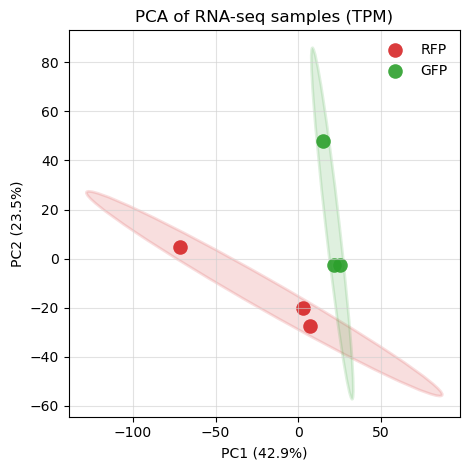

Saved: PCA_TPM_GFPpos_RFPneg.svg
group
RFP    3
GFP    3
Name: count, dtype: int64


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse

# ======================
# Input / Output
# ======================
TPM_PATH = "tpms.tsv"
OUT_SVG = "PCA_TPM_GFPpos_RFPneg.svg"

# ======================
# Plot settings
# ======================
# Colors: GFP+ in green, GFP− (i.e., RFP) in redCOLOR_MAP = {
    "GFP": "#2CA02C",   # green
    "RFP": "#D62728",   # red
    "Other": "#B0B0B0"
}

DOT_SIZE = 110
ELLIPSE_ALPHA = 0.15
ELLIPSE_LW = 2.0

# PCA settings
TOP_VAR_GENES = 3000  # Top variable genes (recommended)
mpl.rcParams["svg.fonttype"] = "none"  # For Illustrator

# ======================
# Helper: group inference
# ======================
def infer_group(sample: str) -> str:
    # Definition used here: GFP− corresponds to RFP (red), GFP+ corresponds to GFP (green)
    if "GFP-" in sample:
        return "RFP"
    if "GFP+" in sample:
        return "GFP"
    return "Other"

# ======================
# Helper: confidence ellipse (95%)
# ======================
def add_confidence_ellipse(ax, x, y, color, alpha=0.15, lw=2.0):
    """
 Draw a 95% confidence ellipse assuming a 2D Gaussian distribution.
Does not require sklearn. Recommended for n ≥ 3 samples.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) < 3:
        return  # Do not draw the ellipse if there are too few points (unstable)

    cov = np.cov(x, y)
    if not np.all(np.isfinite(cov)):
        return

    # Eigen decomposition
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    # 95% (chi-square, df=2) ≈ 5.991
    chi2_val = 5.991
    width, height = 2.0 * np.sqrt(vals * chi2_val)

    # Rotation angle of the ellipse
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    ell = Ellipse(
        (np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=angle,
        facecolor=color,
        edgecolor=color,
        alpha=alpha,
        lw=lw
    )
    ax.add_patch(ell)

# ======================
# Load TPM
# ======================
expr = pd.read_csv(TPM_PATH, sep="\t", index_col=0)

# log2(TPM + 1)
expr_log = np.log2(expr + 1)

# samples x genes
X = expr_log.T
samples = X.index.to_list()

# ======================
# High-variance genes (recommended)
# ======================
var = X.var(axis=0)
top_genes = var.sort_values(ascending=False).head(TOP_VAR_GENES).index
X = X.loc[:, top_genes]

# ======================
# Standardize (gene-wise)
# ======================
Xv = X.values
Xv = (Xv - Xv.mean(axis=0)) / Xv.std(axis=0, ddof=1)

# ======================
# PCA via SVD
# ======================
U, S, Vt = np.linalg.svd(Xv, full_matrices=False)
PCs = U[:, :2] * S[:2]
var_explained = (S**2) / np.sum(S**2)

pc_df = pd.DataFrame(PCs, index=samples, columns=["PC1", "PC2"])
pc_df["group"] = [infer_group(s) for s in samples]

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(4.8, 4.8))

# Scatter by group
for g in ["RFP", "GFP", "Other"]:
    sub = pc_df[pc_df["group"] == g]
    if sub.empty:
        continue
    ax.scatter(
        sub["PC1"], sub["PC2"],
        s=DOT_SIZE,
        color=COLOR_MAP[g],
        label=g,
        alpha=0.9,
        linewidths=0
    )

# Ellipses (RFP and GFP only)
for g in ["RFP", "GFP"]:
    sub = pc_df[pc_df["group"] == g]
    if len(sub) >= 3:
        add_confidence_ellipse(
            ax,
            sub["PC1"].values,
            sub["PC2"].values,
            color=COLOR_MAP[g],
            alpha=ELLIPSE_ALPHA,
            lw=ELLIPSE_LW
        )

# Labels (optional debug; keep commented for final figure)
# for s in pc_df.index:
#     ax.text(pc_df.loc[s, "PC1"], pc_df.loc[s, "PC2"], s, fontsize=8, ha="left", va="bottom")

ax.set_xlabel(f"PC1 ({var_explained[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({var_explained[1]*100:.1f}%)")
ax.set_title("PCA of RNA-seq samples (TPM)")
# Add grid lines
ax.grid(
    True,
    which="both",
    axis="both",
    color="#D0D0D0",
    linewidth=0.8,
    alpha=0.6,
    zorder=0
)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(OUT_SVG)
plt.show()

print("Saved:", OUT_SVG)
print(pc_df["group"].value_counts())


Significant UP genes: 378
Myogenic UP genes matched: 17


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


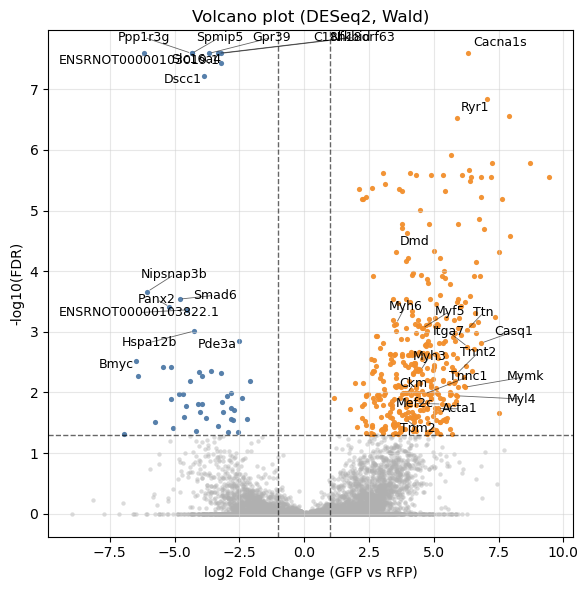

Saved: volcano_GFP_vs_RFP.svg
Labeled down genes: 15 (top 15)
Labeled up genes (myogenic only): 17 (top 20)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from adjustText import adjust_text

# ======================
# Settings
# ======================
DE_PATH = "DE.tsv"
SVG_OUT = "volcano_GFP_vs_RFP.svg"

LOG2FC_CUTOFF = 1.0
FDR_CUTOFF = 0.05

LABEL_DOWN_TOP_N = 15
LABEL_UP_TOP_N   = 20       # Automatically reduced if few myogenic candidates are present
LABEL_FONT_SIZE  = 9

POINT_SIZE_NS = 10
POINT_SIZE_SIG = 14

COLOR_NS = "#B0B0B0"       # gray
COLOR_UP = "#F28E2B"       # orange
COLOR_DN = "#4E79A7"       # blue

# List of myogenic and muscle-lineage–associated genes
MYOGENIC_GENES = {
    "Pax7","Myod1","Myog","Myf5","Myf6","Myf5",
    "Des","Acta1","Tnnt1","Tnnt2","Tnnc1","Tnni1","Tnni2",
    "Myh1","Myh2","Myh3","Myh4","Myh6","Myh7","Myh8","Cdkn1a",
    "Myl1","Myl2","Myl3","Myl4",
    "Ckm","Tpm1","Tpm2","Tpm3","Mymk",
    "Neb","Ttn",
    "Cacna1s","Ryr1","Atp2a1","Atp2a2","Casq1","Casq2",
    "Dmd","Dysf","Dag1","Sgca","Sgcb","Sgcd","Sgsg",
    "Itga7","Vcam1",
    "Mef2c","Mef2d",

    # ---- myoblast fusion machinery ----
    "Myomaker","Tmem8c",
    "Myomixer","Myomerger","Minion"
}

# Keep text as text objects in SVG (for Adobe Illustrator editing)
mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Load and preprocess data
# ======================
df = pd.read_csv(DE_PATH, sep="\t").rename(columns={"Unnamed: 0": "Ensembl"})

# Check required columns
required_cols = ["Symbol", "log2FC", "padj"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Found: {df.columns.tolist()}")

df["Symbol"] = df["Symbol"].astype(str)
df["log2FC"] = pd.to_numeric(df["log2FC"], errors="coerce")
df["padj"] = pd.to_numeric(df["padj"], errors="coerce")
df = df.dropna(subset=["log2FC", "padj"]).copy()

# Compute -log10(FDR)
df["neglog10"] = -np.log10(df["padj"].clip(lower=1e-300))

# Define significance categories
sig = (df["padj"] < FDR_CUTOFF) & (df["log2FC"].abs() >= LOG2FC_CUTOFF)
up = sig & (df["log2FC"] > 0)
dn = sig & (df["log2FC"] < 0)
ns = ~sig

# ======================
# Select genes to label
# ======================
# Downregulated genes: top-ranked by adjusted p-value
label_down_df = (
    df.loc[dn]
      .sort_values(["padj", "log2FC"], ascending=[True, True])
      .drop_duplicates(subset=["Symbol"])
      .head(LABEL_DOWN_TOP_N)
)

# Upregulated genes: restricted to myogenic genes only
up_df = df.loc[up].copy()
up_df["is_myogenic"] = up_df["Symbol"].isin(MYOGENIC_GENES)

label_up_df = (
    up_df[up_df["is_myogenic"]]
      .sort_values(["padj", "log2FC"], ascending=[True, False])
      .drop_duplicates(subset=["Symbol"])
      .head(LABEL_UP_TOP_N)
)

# Report how many genes were captured (useful for figure description)
print("Significant UP genes:", int(up.sum()))
print("Myogenic UP genes matched:", len(label_up_df))

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(6, 6))

# Non-significant genes
ax.scatter(df.loc[ns, "log2FC"], df.loc[ns, "neglog10"],
           s=POINT_SIZE_NS, alpha=0.45, c=COLOR_NS, linewidths=0)

# Upregulated significant genes
ax.scatter(df.loc[up, "log2FC"], df.loc[up, "neglog10"],
           s=POINT_SIZE_SIG, alpha=0.95, c=COLOR_UP, linewidths=0)

# Downregulated significant genes
ax.scatter(df.loc[dn, "log2FC"], df.loc[dn, "neglog10"],
           s=POINT_SIZE_SIG, alpha=0.95, c=COLOR_DN, linewidths=0)

# Threshold lines
ax.axvline(LOG2FC_CUTOFF, linestyle="--", linewidth=1, color="black", alpha=0.6)
ax.axvline(-LOG2FC_CUTOFF, linestyle="--", linewidth=1, color="black", alpha=0.6)
ax.axhline(-np.log10(FDR_CUTOFF), linestyle="--", linewidth=1, color="black", alpha=0.6)

# ======================
# Labels with automatic collision avoidance
# ======================
texts = []

for _, r in label_down_df.iterrows():
    texts.append(
        ax.text(r["log2FC"], r["neglog10"], str(r["Symbol"]),
                fontsize=LABEL_FONT_SIZE, ha="right", va="bottom")
    )

for _, r in label_up_df.iterrows():
    texts.append(
        ax.text(r["log2FC"], r["neglog10"], str(r["Symbol"]),
                fontsize=LABEL_FONT_SIZE, ha="left", va="bottom")
    )

adjust_text(
    texts,
    ax=ax,
    expand_text=(1.05, 1.15),
    expand_points=(1.05, 1.20),
    force_text=(0.2, 0.35),
    force_points=(0.2, 0.35),
    lim=500,
    arrowprops=dict(arrowstyle="-", color="black", lw=0.6, alpha=0.6)
)

# Axis labels and title
ax.set_xlabel("log2 Fold Change (GFP vs RFP)")
ax.set_ylabel("-log10(FDR)")
ax.set_title("Volcano plot (DESeq2, Wald)")

# Grid
ax.grid(True, color="#D0D0D0", linewidth=0.8, alpha=0.5)

# Save figure
fig.tight_layout()
fig.savefig(SVG_OUT, format="svg")
plt.show()

print("Saved:", SVG_OUT)
print(f"Labeled down genes: {len(label_down_df)} (top {LABEL_DOWN_TOP_N})")
print(f"Labeled up genes (myogenic only): {len(label_up_df)} (top {LABEL_UP_TOP_N})")

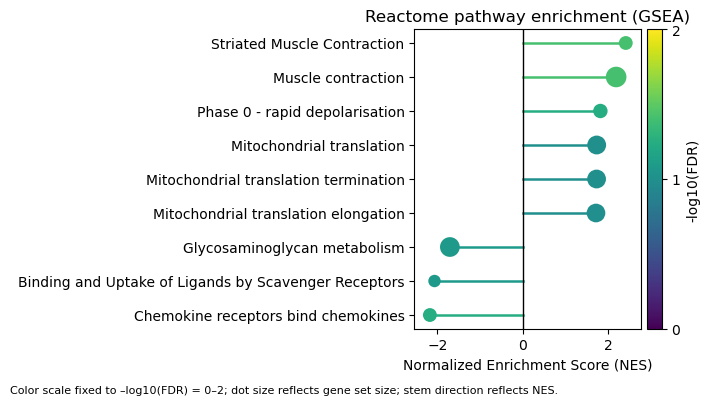

Saved: reactome_gsea_lollipop.svg
Rows plotted: 9
Up pathways: 6 Down pathways: 3
Size column used: size
Colorbar range: (0.0, 2.0)


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ======================
# Final
# ======================
IN_PATH = "GSEA_PathResults.tsv"
SVG_OUT = "reactome_gsea_lollipop.svg"

TOP_N_DOWN = 12
TOP_N_UP   = 6

STEM_LW = 1.8
MIN_S = 80
MAX_S = 220

CMAP = "viridis"

# Color scale for -log10(FDR)
CBAR_VMIN = 0.0
CBAR_VMAX = 2.0   # ★ 2 をカラーバー最上端（黄色）に割り当てる

mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Load
# ======================
df = pd.read_csv(IN_PATH, sep="\t")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df[df["Database"] == "REACTOME"].copy()

for c in ["NES", "padj", "p-value", "size", "numGenes"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["NES", "padj"]).copy()

# 重複Pathway名を統合（|NES|最大）
df = (
    df.sort_values("NES", key=lambda x: x.abs(), ascending=False)
      .drop_duplicates(subset=["Pathway"])
)

down = df[df["NES"] < 0].sort_values("padj").head(TOP_N_DOWN)
up   = df[df["NES"] > 0].sort_values("padj").head(TOP_N_UP)

plot_df = pd.concat([down, up], axis=0).copy()
plot_df["neglog10FDR"] = -np.log10(plot_df["padj"].clip(lower=1e-300))
plot_df = plot_df.sort_values("NES").reset_index(drop=True)

# ======================
# Dot size = gene set size
# ======================
size_col = "size"
if size_col not in plot_df.columns or plot_df[size_col].isna().all():
    size_col = "numGenes" if "numGenes" in plot_df.columns and not plot_df["numGenes"].isna().all() else None

if size_col is None:
    size_scaled = np.full(len(plot_df), (MIN_S + MAX_S) / 2)
else:
    raw = pd.to_numeric(plot_df[size_col], errors="coerce").fillna(0).to_numpy()
    s0 = np.sqrt(raw)
    den = float(np.nanmax(s0) - np.nanmin(s0))
    if den < 1e-12:
        size_scaled = np.full_like(s0, (MIN_S + MAX_S) / 2)
    else:
        t = (s0 - float(np.nanmin(s0))) / den
        size_scaled = MIN_S + (MAX_S - MIN_S) * t

# ======================
# Color = -log10(FDR) 〔0–2 固定〕
# ======================
cvals = plot_df["neglog10FDR"].to_numpy(dtype=float)

# ★ ここが重要：2 が viridis の最上端（黄色）になる
norm = Normalize(vmin=CBAR_VMIN, vmax=CBAR_VMAX, clip=True)
cmap = plt.get_cmap(CMAP)
rgba = cmap(norm(cvals))  # バー・ドット共通色

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(7, 0.45 * len(plot_df)))
y = np.arange(len(plot_df))

# Stem（バー）
for i, r in enumerate(plot_df.itertuples()):
    ax.plot(
        [0, r.NES], [i, i],
        color=rgba[i],
        linewidth=STEM_LW,
        alpha=1.0,
        zorder=1
    )

# Dot（円）
ax.scatter(
    plot_df["NES"], y,
    s=size_scaled,
    c=rgba,
    linewidths=0,
    zorder=3
)

# 中央線
ax.axvline(0, color="black", linewidth=1)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Pathway"])
ax.set_xlabel("Normalized Enrichment Score (NES)")
ax.set_title("Reactome pathway enrichment (GSEA)")

# x軸余白
xmin, xmax = float(plot_df["NES"].min()), float(plot_df["NES"].max())
xrange = max(1e-9, xmax - xmin)
pad = max(0.25, 0.08 * xrange)
ax.set_xlim(xmin - pad, xmax + pad)

# Colorbar（0–2 固定）
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("-log10(FDR)")
cbar.set_ticks([0, 1, 2])

# 注釈（下側）
fig.text(
    0.01, 0.01,
    "Color scale fixed to –log10(FDR) = 0–2; dot size reflects gene set size; stem direction reflects NES.",
    ha="left", va="bottom", fontsize=8
)

# ★ Pathway名が切れないように：tight_layoutで左余白を自動確保しつつ、下に注釈分の余白も確保
fig.tight_layout(rect=[0.00, 0.03, 1.00, 1.00])

# SVG出力
fig.savefig(SVG_OUT)
plt.show()

print("Saved:", SVG_OUT)
print("Rows plotted:", len(plot_df))
print("Up pathways:", int((plot_df["NES"] > 0).sum()),
      "Down pathways:", int((plot_df["NES"] < 0).sum()))
print("Size column used:", size_col)
print("Colorbar range:", (CBAR_VMIN, CBAR_VMAX))
